# Customers Like You: ML analysis (ML1 to ML7)

Run `python build_matrix.py` first. Then run this notebook top to bottom (Kernel > Restart & Run All).
All results land in `results/` and all figures in `figures/`. No customer IDs appear in either (R4).

In [1]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import recsys as rs

np.random.seed(rs.SEED)
Path("results").mkdir(exist_ok=True)
Path("figures").mkdir(exist_ok=True)
pd.set_option("display.max_colwidth", 120)

VALUE = "binary"   # cell value; chosen on the validation split (see ML7 and DECISIONS D10)
A, customers, products, holdout, report = rs.load(VALUE)
print(json.dumps(report, indent=2))

{
  "shape": [
    5471,
    3686
  ],
  "non_zeros": 413691,
  "sparsity_pct": 97.949,
  "avg_products_per_customer": 75.6,
  "dense_MB_float64": 161.3,
  "sparse_MB_csr": 4.99,
  "factors_MB_k50": 3.66,
  "purchase_value": "binary",
  "min_customers_per_product": 10,
  "test_cutoff": "2011-10-09",
  "test_months": 2,
  "products_dropped_by_filter": 843,
  "test_customer_product_pairs": 95278,
  "pairs_with_known_customer": 81438,
  "pairs_new_to_customer": 49684,
  "pairs_new_and_in_catalogue": 44922,
  "eval_customers": 1913,
  "build_seconds": 5.6
}


## ML1: Method decision (written before running anything)

**Main model: Truncated SVD.**

1. The matrix is over 98% zeros. Truncated SVD works directly on the sparse matrix. PCA must
   subtract the average customer first, which turns every zero into a small negative number, so
   the data stops being sparse. Modern solvers centre implicitly, but they still pay for it in
   time and memory.
2. One fit gives us both customer factors (U·S) and product factors (V). Product factors are
   exactly what the "also bought" box needs.
3. PCA describes *how a customer differs from the average customer*. For recommendations we care
   about *what a customer actually buys*, and zeros should mean "didn't buy", not
   "bought less than average".

**What would change my mind:** if PCA gave a clearly higher validation hit rate at the same k.
ML5 checks this.

## ML2: How much do we lose at each k? Which k do we keep?

* **Left plot:** reconstruction error on the full training matrix (what compression throws away).
* **Right plot:** hit rate on a *validation* split, i.e. the last 2 months *of the training
  period*. We pick k here, so the real test set is used only once, at the end (R2).

**Rule for choosing k:** the smallest k whose validation hit rate is within 1 percentage point
of the best one. Smaller k means a smaller table and a faster job.

In [2]:
val_mats, val_products, val_hold, val_stats = rs.validation_split()
A_val = val_mats[VALUE]
print("validation set:", val_stats)
# k must be smaller than the number of products (only matters on tiny test data)
KS = [k for k in [10, 20, 50, 100, 200] if k < min(A.shape + A_val.shape) - 1]

rows = []
for k in KS:
    svd, svd_s, svd_mb = rs.fit_svd(A, k)
    pca, pca_s, pca_mb = rs.fit_pca(A, k)
    svd_val, _, _ = rs.fit_svd(A_val, k)
    hr = rs.evaluate(A_val, svd_val, val_hold)["model"]
    rows.append({"k": k,
                 "svd_rel_error": rs.relative_error(A, svd),
                 "svd_explained_var": float(svd.explained_variance_ratio_.sum()),
                 "pca_rel_error": rs.relative_error(A, pca),
                 "pca_explained_var": float(pca.explained_variance_ratio_.sum()),
                 "svd_fit_s": svd_s, "pca_fit_s": pca_s,
                 "factors_MB": rs.factors_mb(A, k),
                 "val_hit_rate_svd": hr["hit_rate"]})
    print(f"k={k:>3}  done")
sweep = pd.DataFrame(rows)
_, val_base = rs.recommend_bestsellers(A_val, val_products["n_customers"],
                                       np.sort(val_hold["customer_idx"].unique()))
val_baseline = rs.hit_rate(np.sort(val_hold["customer_idx"].unique()), val_base, val_hold)["hit_rate"]

best = sweep["val_hit_rate_svd"].max()
K = int(sweep.loc[sweep["val_hit_rate_svd"] >= best - 0.01, "k"].min())
sweep.to_csv("results/k_sweep.csv", index=False)
print(f"\nChosen k = {K}  (validation best {best:.1%}, best-seller baseline {val_baseline:.1%})")
sweep.round(4)

validation set: {'val_cutoff': '2011-08-07', 'test_customer_product_pairs': 64198, 'pairs_with_known_customer': 53812, 'pairs_new_to_customer': 30236, 'pairs_new_and_in_catalogue': 24847, 'eval_customers': 1415}


k= 10  done


k= 20  done


k= 50  done


k=100  done


k=200  done

Chosen k = 50  (validation best 41.8%, best-seller baseline 26.4%)


,k,svd_rel_error,svd_explained_var,pca_rel_error,pca_explained_var,svd_fit_s,pca_fit_s,factors_MB,val_hit_rate_svd
0,10,0.8980,0.1540,0.8976,0.1544,0.1257,0.1320,0.7326,0.3491
1,20,0.8759,0.1951,0.8755,0.1956,0.1051,0.1620,1.4651,0.3951
2,50,0.8324,0.2730,0.8316,0.2742,0.2579,0.4139,3.6628,0.4092
3,100,0.7812,0.3595,0.7799,0.3617,0.4931,0.8740,7.3256,0.4177
4,200,0.7027,0.4818,0.7007,0.4848,0.8809,1.7610,14.6512,0.4049


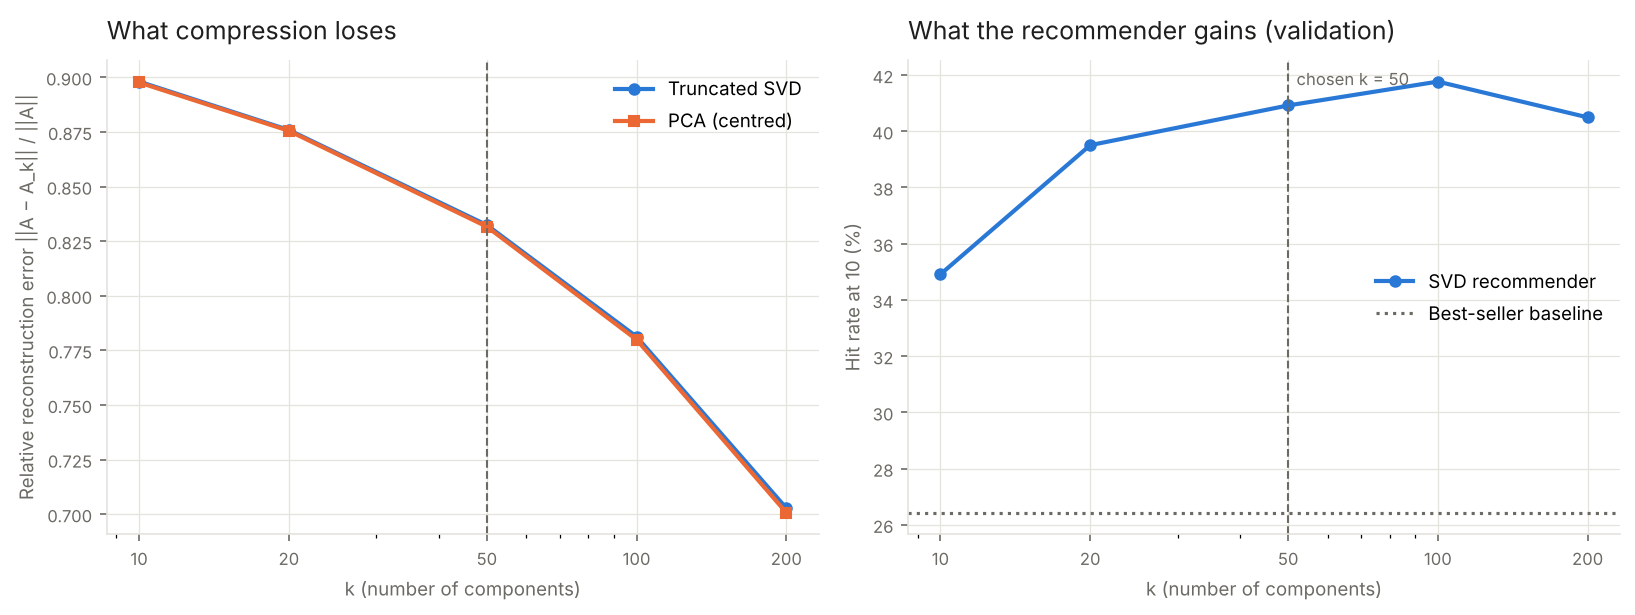

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2), dpi=150)
ax1.plot(sweep.k, sweep.svd_rel_error, marker="o", ms=5, lw=2, color=rs.PALETTE[0], label="Truncated SVD")
ax1.plot(sweep.k, sweep.pca_rel_error, marker="s", ms=5, lw=2, color=rs.PALETTE[1], label="PCA (centred)")
rs._style(ax1, "What compression loses", "k (number of components)",
          "Relative reconstruction error ||A − A_k|| / ||A||")
ax1.set_xscale("log"); ax1.set_xticks(KS); ax1.set_xticklabels(KS)
ax1.legend(frameon=False, fontsize=9)
ax1.axvline(K, color=rs.MUTED, lw=1, ls="--")

ax2.plot(sweep.k, sweep.val_hit_rate_svd * 100, marker="o", ms=5, lw=2, color=rs.PALETTE[0], label="SVD recommender")
ax2.axhline(val_baseline * 100, color=rs.MUTED, lw=1.5, ls=":", label="Best-seller baseline")
rs._style(ax2, "What the recommender gains (validation)", "k (number of components)", "Hit rate at 10 (%)")
ax2.set_xscale("log"); ax2.set_xticks(KS); ax2.set_xticklabels(KS)
ax2.axvline(K, color=rs.MUTED, lw=1, ls="--")
ax2.annotate(f"chosen k = {K}", (K, ax2.get_ylim()[1]), xytext=(4, -12), textcoords="offset points",
             fontsize=8, color=rs.MUTED)
ax2.legend(frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig("figures/k_curve.png", bbox_inches="tight")

## ML3: Recommendations

* **Product page box:** the 10 products whose factor vectors have the highest cosine similarity.
* **For a customer:** take their row of the compressed matrix, A_k = U·S·Vᵀ. Compression fills in
  the blanks with "what customers like you buy". We show the 10 highest products they haven't
  bought yet. On validation this beat summing cosine similarities (DECISIONS D13).

The sanity check below shows the neighbours of the 5 most popular products. They should look
like things a shop would plausibly buy together.

In [4]:
svd, _, _ = rs.fit_svd(A, K)
P = rs.product_vectors(svd)
desc = products["Description"].fillna(products["StockCode"]).to_numpy()
examples = []
for j in np.argsort(-products["n_customers"].to_numpy())[:5]:
    for rank, nb in enumerate(rs.similar_products(P, j)[:5], 1):
        examples.append({"product": desc[j], "rank": rank, "also_bought": desc[nb]})
examples = pd.DataFrame(examples)
examples.to_csv("results/example_neighbours.csv", index=False)
examples

,product,rank,also_bought
0,WHITE HANGING HEART T-LIGHT HOLDER,1,RED HANGING HEART T-LIGHT HOLDER
1,WHITE HANGING HEART T-LIGHT HOLDER,2,CANDLEHOLDER PINK HANGING HEART
2,WHITE HANGING HEART T-LIGHT HOLDER,3,ZINC METAL HEART DECORATION
3,WHITE HANGING HEART T-LIGHT HOLDER,4,CREAM HEART CARD HOLDER
4,WHITE HANGING HEART T-LIGHT HOLDER,5,HANGING METAL HEART LANTERN
5,REGENCY CAKESTAND 3 TIER,1,ROSES REGENCY TEACUP AND SAUCER
6,REGENCY CAKESTAND 3 TIER,2,GREEN REGENCY TEACUP AND SAUCER
7,REGENCY CAKESTAND 3 TIER,3,PINK REGENCY TEACUP AND SAUCER
8,REGENCY CAKESTAND 3 TIER,4,SET OF 3 REGENCY CAKE TINS
9,REGENCY CAKESTAND 3 TIER,5,REGENCY TEAPOT ROSES


## ML4: Final evaluation on held-out test purchases (touched once)

**Hit rate at 10:** the share of test customers for whom at least one product they bought *for
the first time* in the last 2 months appears in our top 10. The **baseline** gives every
customer the 10 best sellers they don't already own.

In [5]:
test_res = rs.evaluate(A, svd, holdout, products["n_customers"])
job = rs.nightly_job(A, K, "svd")
results = pd.DataFrame({
    "approach": [f"Truncated SVD, k={K}", "Best sellers (baseline)"],
    "hit_rate_at_10": [test_res["model"]["hit_rate"], test_res["bestsellers"]["hit_rate"]],
    "ci95_plus_minus": [test_res["model"]["ci95"], test_res["bestsellers"]["ci95"]],
    "test_customers": [test_res["model"]["n_customers"]] * 2,
})
results.to_csv("results/test_results.csv", index=False)
print("Nightly job:", {k: (round(v, 2) if isinstance(v, float) else v) for k, v in job.items()})
results

Nightly job: {'fit_s': 0.27, 'product_neighbours_s': 0.23, 'score_all_customers_s': 0.3, 'total_s': 0.79, 'peak_fit_MB': 9.71, 'neighbour_table_shape': [3686, 10]}


,approach,hit_rate_at_10,ci95_plus_minus,test_customers
0,"Truncated SVD, k=50",0.394145,0.021898,1913
1,Best sellers (baseline),0.270256,0.019901,1913


## ML5: PCA vs Truncated SVD, same matrix, same k

In [6]:
pca, pca_s, pca_mb = rs.fit_pca(A, K)
svd_fit, svd_s, svd_mb = rs.fit_svd(A, K)
pca_test = rs.evaluate(A, pca, holdout)["model"]
c1_svd = rs.describe_component_1(A, svd, products)
c1_pca = rs.describe_component_1(A, pca, products)

def c1_words(c):
    return (f"{c['share_of_products_with_same_sign']:.0%} of products load the same way; "
            f"corr. with customer volume {c['corr_with_customer_volume']:.2f}; "
            f"top: {', '.join(c['top_positive'][:3])}")

comparison = pd.DataFrame({
    "Measure": ["k used", "Fit time (seconds)", "Peak memory during fit (MB)", "Size of stored factors (MB)",
                "Relative reconstruction error", "Variance explained", "Hit rate at 10 on held-out purchases",
                "Best-seller baseline hit rate at 10", "What component 1 represents (evidence)"],
    "PCA": [K, round(pca_s, 2), round(pca_mb, 1), round(rs.factors_mb(A, K), 2),
            round(rs.relative_error(A, pca), 4), round(float(pca.explained_variance_ratio_.sum()), 4),
            f"{pca_test['hit_rate']:.1%}", f"{test_res['bestsellers']['hit_rate']:.1%}", c1_words(c1_pca)],
    "Truncated SVD": [K, round(svd_s, 2), round(svd_mb, 1), round(rs.factors_mb(A, K), 2),
                      round(rs.relative_error(A, svd_fit), 4), round(float(svd_fit.explained_variance_ratio_.sum()), 4),
                      f"{test_res['model']['hit_rate']:.1%}", f"{test_res['bestsellers']['hit_rate']:.1%}",
                      c1_words(c1_svd)],
})
comparison.to_csv("results/pca_vs_svd.csv", index=False)
json.dump({"svd": c1_svd, "pca": c1_pca}, open("results/component_1.json", "w"), indent=2)
comparison

,Measure,PCA,Truncated SVD
0,k used,50,50
1,Fit time (seconds),0.44,0.23
2,Peak memory during fit (MB),7.7,9.7
3,Size of stored factors (MB),3.66,3.66
4,Relative reconstruction error,0.8316,0.8324
5,Variance explained,0.2742,0.273
6,Hit rate at 10 on held-out purchases,40.7%,39.4%
7,Best-seller baseline hit rate at 10,27.0%,27.0%
8,What component 1 represents (evidence),"100% of products load the same way; corr. with customer volume 0.98; top: PACK OF 72 RETRO SPOT CAKE CASES, LUNCH BA...","100% of products load the same way; corr. with customer volume 0.98; top: WHITE HANGING HEART T-LIGHT HOLDER, PACK O..."


**How to read component 1.** If almost all products load the same way and the score correlates
strongly with customer volume, SVD's component 1 means *"how much this customer buys overall"*.
PCA removes the average first, so its component 1 is a *contrast*: one group of products
against another. Write the final sentence for the memo from the numbers above.

## ML6: Customer map for marketing

We cluster on *taste*, not size: each customer's factor vector is scaled to length 1. Silhouette
score picks the number of groups (3 to 6). After the first run, read the profile table and put
real names in `SEGMENT_NAMES`, then re-run this cell.

In [7]:
labels, xy, sil = rs.customer_segments(svd, A)
print("silhouette by number of groups:", {k: round(v, 3) for k, v in sil.items()})
profiles = rs.segment_profiles(labels, A, customers, products)
profiles.to_csv("results/segments.csv", index=False)
profiles

silhouette by number of groups: {3: 0.13, 4: 0.14, 5: 0.149, 6: 0.15}


,segment,customers,pct_customers,median_distinct_products,top_countries,characteristic_products
0,0,1233,22.5,34.0,"United Kingdom 98%, Netherlands 0%, Germany 0%",HEART IVORY TRELLIS LARGE (x2.2) | ZINC METAL HEART DECORATION (x2.2) | HEART OF WICKER LARGE (x2.1) | SINGLE HEART ...
1,1,989,18.1,48.0,"United Kingdom 90%, France 2%, Germany 2%",TRADITIONAL MODELLING CLAY (x3.0) | MINI PAINT SET VINTAGE (x2.9) | PICTURE DOMINOES (x2.8) | MAGIC DRAWING SLATE SP...
2,2,893,16.3,44.0,"United Kingdom 91%, France 1%, Germany 1%",PINK REGENCY TEACUP AND SAUCER (x3.3) | GREEN REGENCY TEACUP AND SAUCER (x3.2) | SET OF 3 REGENCY CAKE TINS (x3.1) |...
3,3,875,16.0,30.0,"United Kingdom 96%, Germany 1%, Cyprus 0%",NO SINGING METAL SIGN (x2.4) | HAND OVER THE CHOCOLATE SIGN (x2.3) | METAL SIGN TAKE IT OR LEAVE IT (x2.2) | GIN +...
4,4,751,13.7,47.0,"United Kingdom 79%, Germany 5%, France 4%",PACK OF 20 SKULL PAPER NAPKINS (x3.6) | SET/6 RED SPOTTY PAPER PLATES (x3.3) | SET/6 RED SPOTTY PAPER CUPS (x3.2) | ...
5,5,730,13.3,57.0,"United Kingdom 89%, Germany 2%, France 2%",JUMBO BAG PEARS (x4.7) | JUMBO BAG APPLES (x4.7) | JUMBO BAG SPACEBOY DESIGN (x4.4) | JUMBO BAG DOLLY GIRL DESIGN (x...


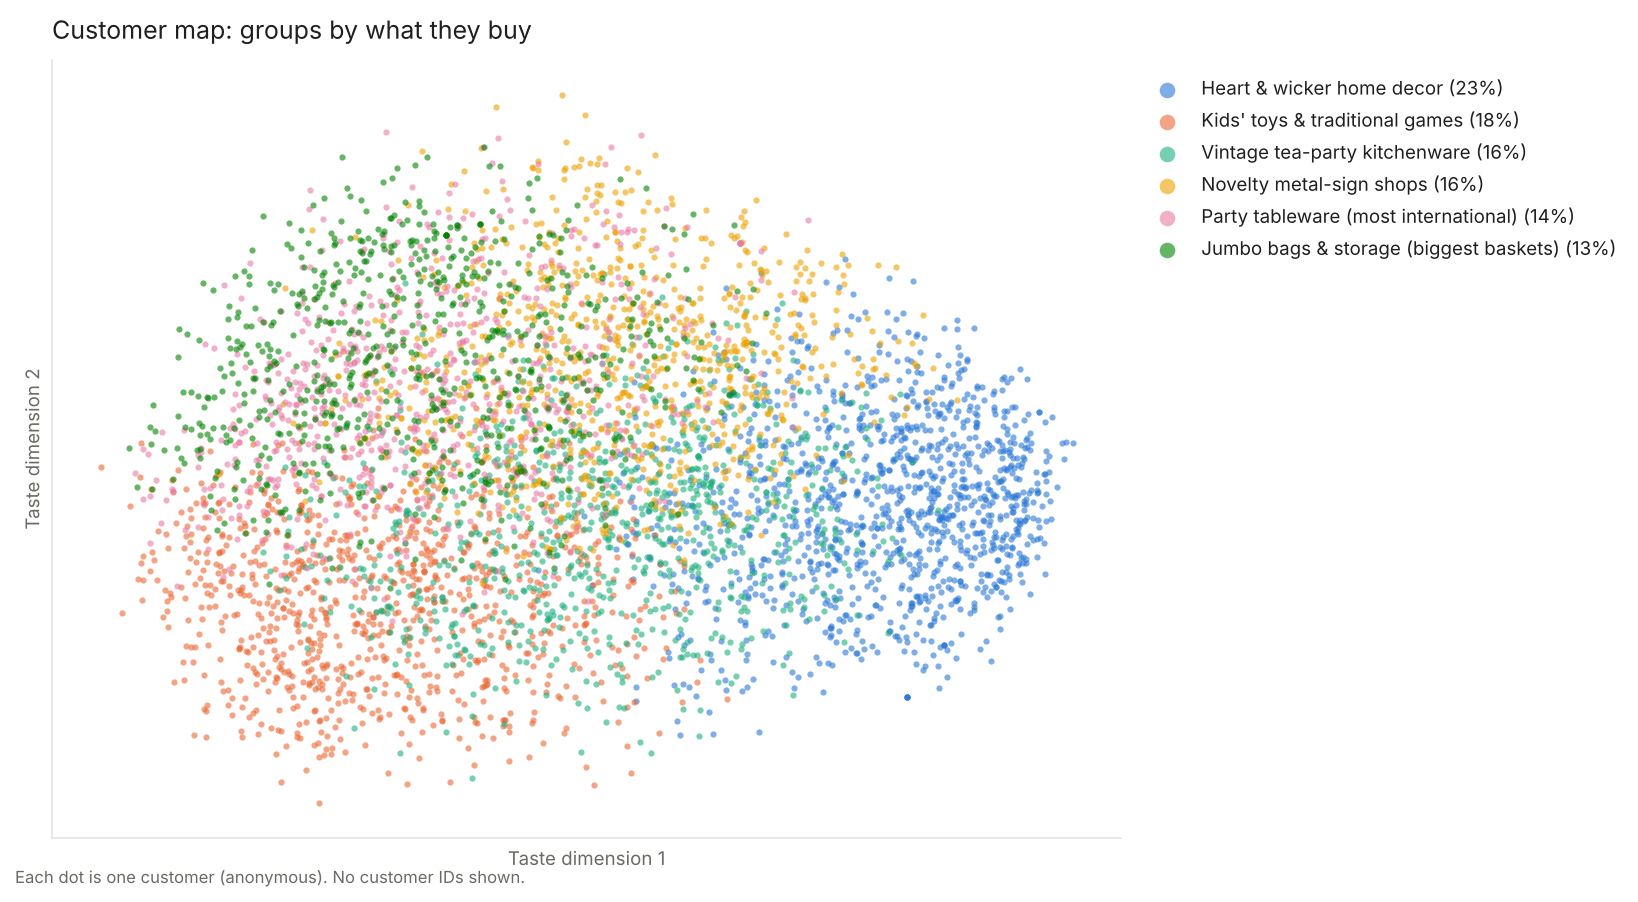

In [8]:
# Fill these in after reading the table above (segment number -> name marketing will use)
SEGMENT_NAMES = {
    0: "Heart & wicker home decor",
    1: "Kids' toys & traditional games",
    2: "Vintage tea-party kitchenware",
    3: "Novelty metal-sign shops",
    4: "Party tableware (most international)",
    5: "Jumbo bags & storage (biggest baskets)",
}
rs.plot_customer_map(xy, labels, SEGMENT_NAMES, "figures/customer_map.png");

## ML7: Sensitivity. Does the purchase value matter?

Same k and same validation split. The purchase value was chosen on **validation** (1/0 won);
test numbers are shown for information only.

In [9]:
sens = []
for v in ["log", "binary", "count"]:
    m_val, _, _ = rs.fit_svd(val_mats[v], K)
    A_v = rs.load(v)[0]
    m_test, _, _ = rs.fit_svd(A_v, K)
    sens.append({"purchase_value": v,
                 "val_hit_rate": rs.evaluate(val_mats[v], m_val, val_hold)["model"]["hit_rate"],
                 "test_hit_rate": rs.evaluate(A_v, m_test, holdout)["model"]["hit_rate"]})
sens = pd.DataFrame(sens)
sens.to_csv("results/sensitivity.csv", index=False)
sens

,purchase_value,val_hit_rate,test_hit_rate
0,log,0.374558,0.374804
1,binary,0.409187,0.394145
2,count,0.206360,0.207527


## Headline numbers for the memo

In [10]:
summary = {
    "k": K,
    "matrix_shape": report["shape"],
    "sparsity_pct": report["sparsity_pct"],
    "dense_MB": report["dense_MB_float64"],
    "sparse_MB": report["sparse_MB_csr"],
    "factors_MB": round(rs.factors_mb(A, K), 2),
    "shrink_factor_vs_dense": round(report["dense_MB_float64"] / rs.factors_mb(A, K), 1),
    "relative_error_svd": round(rs.relative_error(A, svd), 4),
    "hit_rate_svd": round(test_res["model"]["hit_rate"], 4),
    "hit_rate_pca": round(pca_test["hit_rate"], 4),
    "hit_rate_bestsellers": round(test_res["bestsellers"]["hit_rate"], 4),
    "test_customers": test_res["model"]["n_customers"],
    "nightly_job_seconds": round(job["total_s"], 2),
    "n_segments": int(len(np.unique(labels))),
}
json.dump(summary, open("results/summary.json", "w"), indent=2)
summary

{'k': 50,
 'matrix_shape': [5471, 3686],
 'sparsity_pct': 97.949,
 'dense_MB': 161.3,
 'sparse_MB': 4.99,
 'factors_MB': 3.66,
 'shrink_factor_vs_dense': 44.0,
 'relative_error_svd': 0.8324,
 'hit_rate_svd': 0.3941,
 'hit_rate_pca': 0.4072,
 'hit_rate_bestsellers': 0.2703,
 'test_customers': 1913,
 'nightly_job_seconds': 0.79,
 'n_segments': 6}